# Dask Visualization

## 1. Imports and paths

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import configparser
import contextlib
import os
import re
from platform import python_version

import dask
import dask.dataframe as dd
from dask.distributed import Client, LocalCluster

try:
    from dask_cloudprovider.aws import EC2Cluster
except ImportError:
    EC2Cluster = None

warnings.filterwarnings("ignore")
plt.style.use("default")
%matplotlib inline

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FLAT_DIR = PROJECT_ROOT / "ml_outputs" / "flat"
FIG_DIR = PROJECT_ROOT / "ml_outputs" / "visualizations"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Flat output dir:", FLAT_DIR)
print("Figure output dir:", FIG_DIR)
print("Dask version:", dask.__version__)

Project root: /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj
Flat output dir: /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/flat
Figure output dir: /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations
Dask version: 2026.3.0


## 2. Start local Dask client

In [7]:
# Set this to True to use an AWS Dask EC2Cluster like 09_Presentation.
# Important: AWS workers cannot read files from your Mac, so AWS mode reads the CSV outputs from S3.
USE_AWS_DASK = True

AWS_VPC_ID = "vpc-0f662f37683c4219c"
AWS_SECURITY_GROUPS = ["sg-0aec8bcc30b651438"]

def get_aws_credentials():
    parser = configparser.RawConfigParser()
    parser.read(os.path.expanduser("~/.aws/config"))
    config = parser.items("default") if parser.has_section("default") else []

    parser.read(os.path.expanduser("~/.aws/credentials"))
    credentials = parser.items("default") if parser.has_section("default") else []

    all_credentials = {key.upper(): value for key, value in [*config, *credentials]}
    with contextlib.suppress(KeyError):
        all_credentials["AWS_REGION"] = all_credentials.pop("REGION")
    return all_credentials

if USE_AWS_DASK:
    if EC2Cluster is None:
        raise ImportError("Install dask-cloudprovider first: pip install dask-cloudprovider[aws]")

    env_vars = get_aws_credentials()
    env_vars["EXTRA_PIP_PACKAGES"] = "s3fs"

    py_v = "-py" + re.findall(r"\d{1}.\d+", python_version())[0]
    dask_docker_tag = f"daskdev/dask:{dask.__version__ + py_v}"
    print("Docker Image:", dask_docker_tag)

    cluster = EC2Cluster(
        instance_type="r5.large",
        n_workers=4,
        vpc=AWS_VPC_ID,
        security_groups=AWS_SECURITY_GROUPS,
        security=False,
        docker_image=dask_docker_tag,
        env_vars=env_vars,
    )
else:
    cluster = LocalCluster(
        n_workers=4,
        threads_per_worker=1,
        memory_limit="2GB",
        dashboard_address=":0",
    )

client = Client(cluster)
client

Docker Image: daskdev/dask:2026.3.0-py3.10
Creating scheduler instance
Created instance i-0329f63d4f3e03de1 as dask-25903046-scheduler
Waiting for scheduler to run at 13.221.217.215:8786
Scheduler is running
Creating worker instance
Creating worker instance
Creating worker instance
Creating worker instance
Created instance i-0fc7c9e2ac085cacd as dask-25903046-worker-9567717c
Created instance i-0bd72445f257c73ba as dask-25903046-worker-cf5d45ec
Created instance i-0c2147c55b9b4123a as dask-25903046-worker-ae8063fd
Created instance i-03ac06c1df9a2c889 as dask-25903046-worker-c19d20e8


Connection method: Cluster object,Cluster type: dask_cloudprovider.EC2Cluster
Dashboard: http://13.221.217.215:8787/status,
Dashboard: http://13.221.217.215:8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://172.31.35.214:8786,Workers: 0
Dashboard: http://172.31.35.214:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [10]:
client = Client(cluster)
client

<Client: 'tcp://172.31.35.214:8786' processes=4 threads=8, memory=61.30 GiB>

## 3. Load ML output tables with Dask

In [11]:
S3_OUTPUT_BASE = "s3://macs30123-final-pj-yanjing-li-2026/outputs/ml_pipeline"

LOCAL_FILES = {
    "smoke_metrics": FLAT_DIR / "smoke_metrics.csv",
    "full_metrics": FLAT_DIR / "full_metrics.csv",
    "smoke_confusion": FLAT_DIR / "smoke_confusion_matrix.csv",
    "full_confusion": FLAT_DIR / "full_confusion_matrix.csv",
    "smoke_coefficients": FLAT_DIR / "smoke_coefficients.csv",
    "full_coefficients": FLAT_DIR / "full_coefficients.csv",
    "smoke_kmeans_metrics": FLAT_DIR / "smoke_kmeans_metrics.csv",
    "full_kmeans_metrics": FLAT_DIR / "full_kmeans_metrics.csv",
    "smoke_kmeans_summary": FLAT_DIR / "smoke_kmeans_cluster_summary.csv",
    "full_kmeans_summary": FLAT_DIR / "full_kmeans_cluster_summary.csv",
    "smoke_kmeans_centers": FLAT_DIR / "smoke_kmeans_cluster_centers.csv",
    "full_kmeans_centers": FLAT_DIR / "full_kmeans_cluster_centers.csv",
}

S3_FILES = {
    "smoke_metrics": f"{S3_OUTPUT_BASE}/smoke/metrics_csv/part-*.csv",
    "full_metrics": f"{S3_OUTPUT_BASE}/full/metrics_csv/part-*.csv",
    "smoke_confusion": f"{S3_OUTPUT_BASE}/smoke/confusion_matrix_csv/part-*.csv",
    "full_confusion": f"{S3_OUTPUT_BASE}/full/confusion_matrix_csv/part-*.csv",
    "smoke_coefficients": f"{S3_OUTPUT_BASE}/smoke/coefficients_csv/part-*.csv",
    "full_coefficients": f"{S3_OUTPUT_BASE}/full/coefficients_csv/part-*.csv",
    "smoke_kmeans_metrics": f"{S3_OUTPUT_BASE}/smoke_kmeans/metrics_csv/part-*.csv",
    "full_kmeans_metrics": f"{S3_OUTPUT_BASE}/full_kmeans/metrics_csv/part-*.csv",
    "smoke_kmeans_summary": f"{S3_OUTPUT_BASE}/smoke_kmeans/cluster_summary_csv/part-*.csv",
    "full_kmeans_summary": f"{S3_OUTPUT_BASE}/full_kmeans/cluster_summary_csv/part-*.csv",
    "smoke_kmeans_centers": f"{S3_OUTPUT_BASE}/smoke_kmeans/cluster_centers_csv/part-*.csv",
    "full_kmeans_centers": f"{S3_OUTPUT_BASE}/full_kmeans/cluster_centers_csv/part-*.csv",
}

def read_named_csv(name):
    if USE_AWS_DASK:
        return dd.read_csv(S3_FILES[name], storage_options={"anon": False})
    path = LOCAL_FILES[name]
    if not path.exists():
        raise FileNotFoundError(path)
    return dd.read_csv(path)

tables = {
    "smoke_metrics": read_named_csv("smoke_metrics"),
    "full_metrics": read_named_csv("full_metrics"),
    "smoke_confusion": read_named_csv("smoke_confusion"),
    "full_confusion": read_named_csv("full_confusion"),
    "smoke_coefficients": read_named_csv("smoke_coefficients"),
    "full_coefficients": read_named_csv("full_coefficients"),
    "smoke_kmeans_metrics": read_named_csv("smoke_kmeans_metrics"),
    "full_kmeans_metrics": read_named_csv("full_kmeans_metrics"),
    "smoke_kmeans_summary": read_named_csv("smoke_kmeans_summary"),
    "full_kmeans_summary": read_named_csv("full_kmeans_summary"),
    "smoke_kmeans_centers": read_named_csv("smoke_kmeans_centers"),
    "full_kmeans_centers": read_named_csv("full_kmeans_centers"),
}

computed = {name: df.compute() for name, df in tables.items()}
for name, df in computed.items():
    print(f"{name}: {df.shape}")

smoke_metrics: (1, 12)
full_metrics: (1, 12)
smoke_confusion: (4, 3)
full_confusion: (4, 3)
smoke_coefficients: (21, 3)
full_coefficients: (21, 3)
smoke_kmeans_metrics: (1, 6)
full_kmeans_metrics: (1, 6)
smoke_kmeans_summary: (4, 10)
full_kmeans_summary: (4, 10)
smoke_kmeans_centers: (44, 3)
full_kmeans_centers: (44, 3)


## 4. Supervised metrics: smoke vs full

,run_label,target_mode,start_month,end_month,test_auc,test_accuracy,test_f1,best_regParam,best_elasticNetParam,intercept,n_train,n_test
0,smoke,accepted_answer,2022-10,2023-02,0.682289,0.637433,0.623704,0.01,0.0,-2.242299,67476,16622
1,full,accepted_answer,2019-01,2025-03,0.688142,0.638236,0.633809,0.00,0.0,-0.730841,987499,247327


Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_supervised_metrics_smoke_full.png


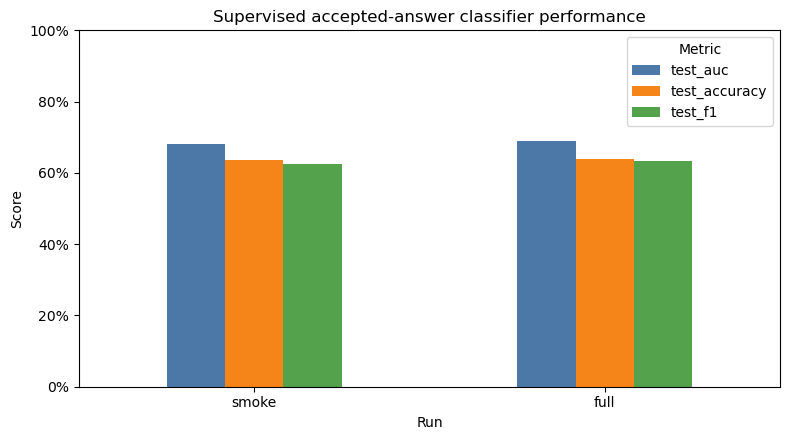

In [12]:
metrics = pd.concat([computed["smoke_metrics"], computed["full_metrics"]], ignore_index=True)
metrics["run_label"] = pd.Categorical(metrics["run_label"], ["smoke", "full"], ordered=True)
metrics = metrics.sort_values("run_label")
display(metrics)

plot_metrics = metrics.set_index("run_label")[["test_auc", "test_accuracy", "test_f1"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_metrics.plot(kind="bar", ax=ax, color=["#4c78a8", "#f58518", "#54a24b"])
ax.set_title("Supervised accepted-answer classifier performance")
ax.set_xlabel("Run")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(title="Metric")
plt.xticks(rotation=0)
plt.tight_layout()

out = FIG_DIR / "ml_supervised_metrics_smoke_full.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
print("Saved", out)
plt.show()

## 5. Confusion matrices

Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_supervised_confusion_matrices.png


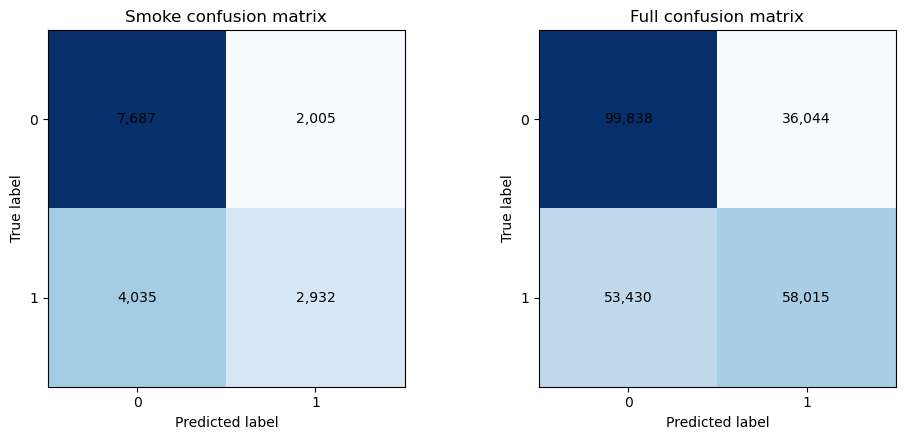

In [13]:
def plot_confusion(confusion, run_label, ax):
    mat = confusion.pivot(index="label", columns="prediction", values="count").fillna(0)
    mat = mat.reindex(index=[0.0, 1.0], columns=[0.0, 1.0], fill_value=0)
    im = ax.imshow(mat.values, cmap="Blues")
    ax.set_title(f"{run_label.capitalize()} confusion matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set_yticks([0, 1], ["0", "1"])
    for i in range(2):
        for j in range(2):
            value = int(mat.values[i, j])
            ax.text(j, i, f"{value:,}", ha="center", va="center", color="black")
    return im

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_confusion(computed["smoke_confusion"], "smoke", axes[0])
plot_confusion(computed["full_confusion"], "full", axes[1])
plt.tight_layout()

out = FIG_DIR / "ml_supervised_confusion_matrices.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
print("Saved", out)
plt.show()

## 6. Logistic regression coefficient magnitude

Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_supervised_top_coefficients.png


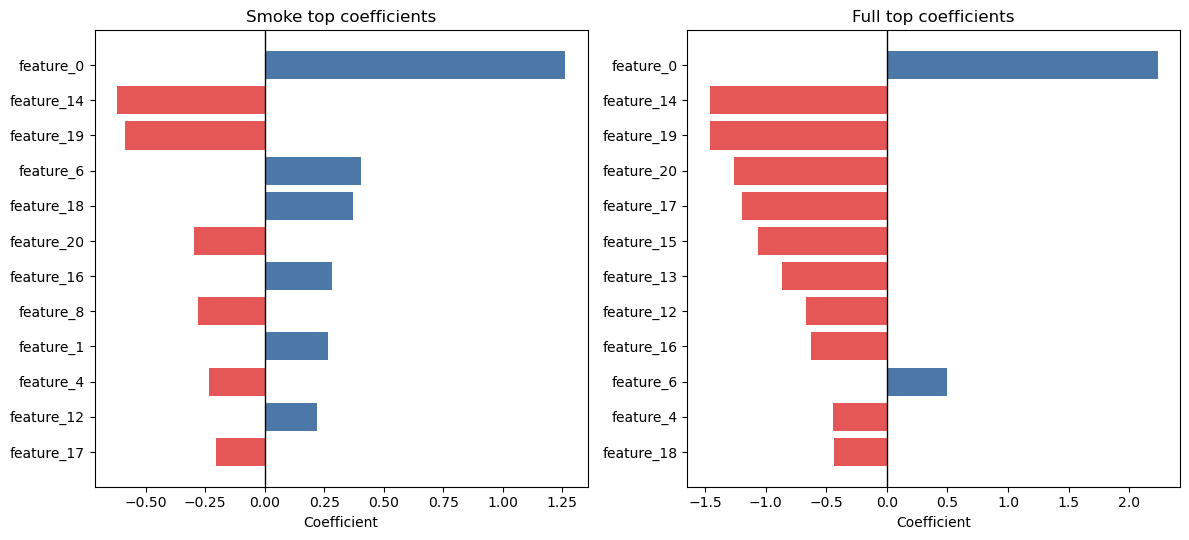

In [14]:
def plot_top_coefficients(coef_df, run_label, ax, n=12):
    top = coef_df.sort_values("abs_coefficient", ascending=False).head(n).iloc[::-1]
    colors = np.where(top["coefficient"] >= 0, "#4c78a8", "#e45756")
    ax.barh(top["feature"], top["coefficient"], color=colors)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{run_label.capitalize()} top coefficients")
    ax.set_xlabel("Coefficient")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_top_coefficients(computed["smoke_coefficients"], "smoke", axes[0])
plot_top_coefficients(computed["full_coefficients"], "full", axes[1])
plt.tight_layout()

out = FIG_DIR / "ml_supervised_top_coefficients.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
print("Saved", out)
plt.show()

## 7. Unsupervised KMeans metrics

,run_label,start_month,end_month,k,silhouette,n_rows
0,smoke,2022-10,2023-02,4,0.338900,84152
1,full,2019-01,2025-03,4,0.474374,1234826


Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_silhouette.png


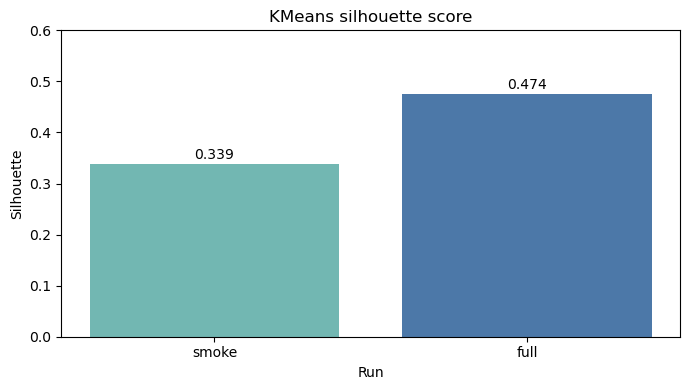

In [15]:
kmeans_metrics = pd.concat([computed["smoke_kmeans_metrics"], computed["full_kmeans_metrics"]], ignore_index=True)
kmeans_metrics["run_label"] = pd.Categorical(kmeans_metrics["run_label"], ["smoke", "full"], ordered=True)
kmeans_metrics = kmeans_metrics.sort_values("run_label")
display(kmeans_metrics)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(kmeans_metrics["run_label"].astype(str), kmeans_metrics["silhouette"], color=["#72b7b2", "#4c78a8"])
ax.set_title("KMeans silhouette score")
ax.set_xlabel("Run")
ax.set_ylabel("Silhouette")
ax.set_ylim(0, max(0.6, kmeans_metrics["silhouette"].max() + 0.05))
for x, y in zip(kmeans_metrics["run_label"].astype(str), kmeans_metrics["silhouette"]):
    ax.text(x, y + 0.01, f"{y:.3f}", ha="center")
plt.tight_layout()

out = FIG_DIR / "ml_kmeans_silhouette.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
print("Saved", out)
plt.show()

## 8. KMeans cluster profiles

Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_smoke_cluster_profiles.png


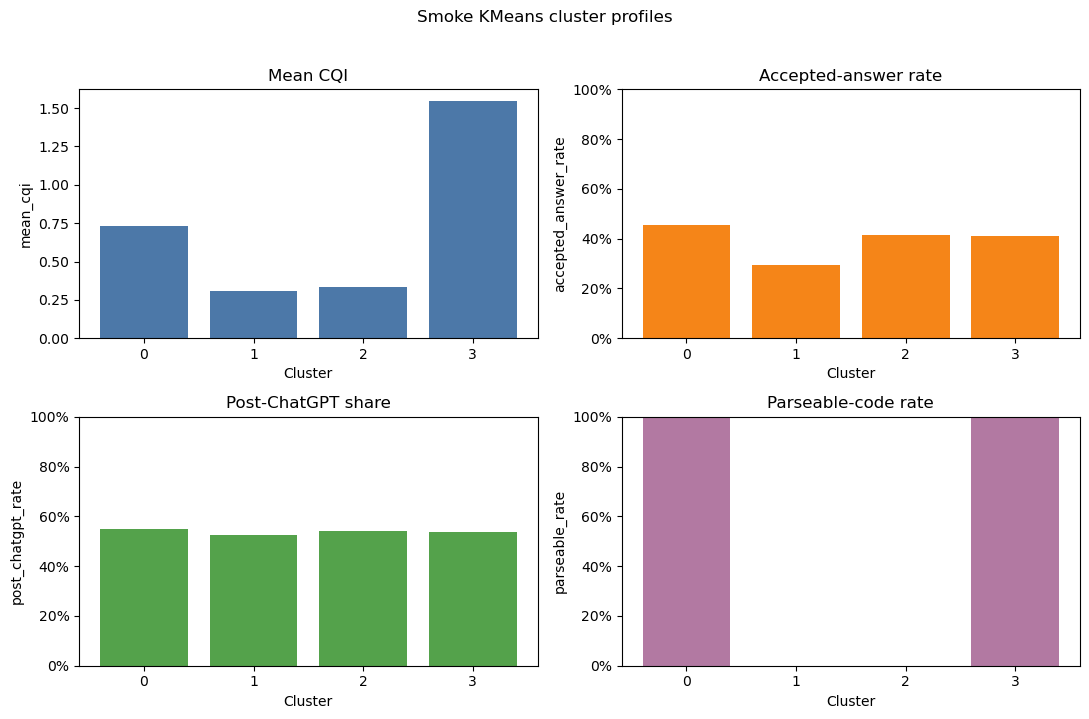

Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_full_cluster_profiles.png


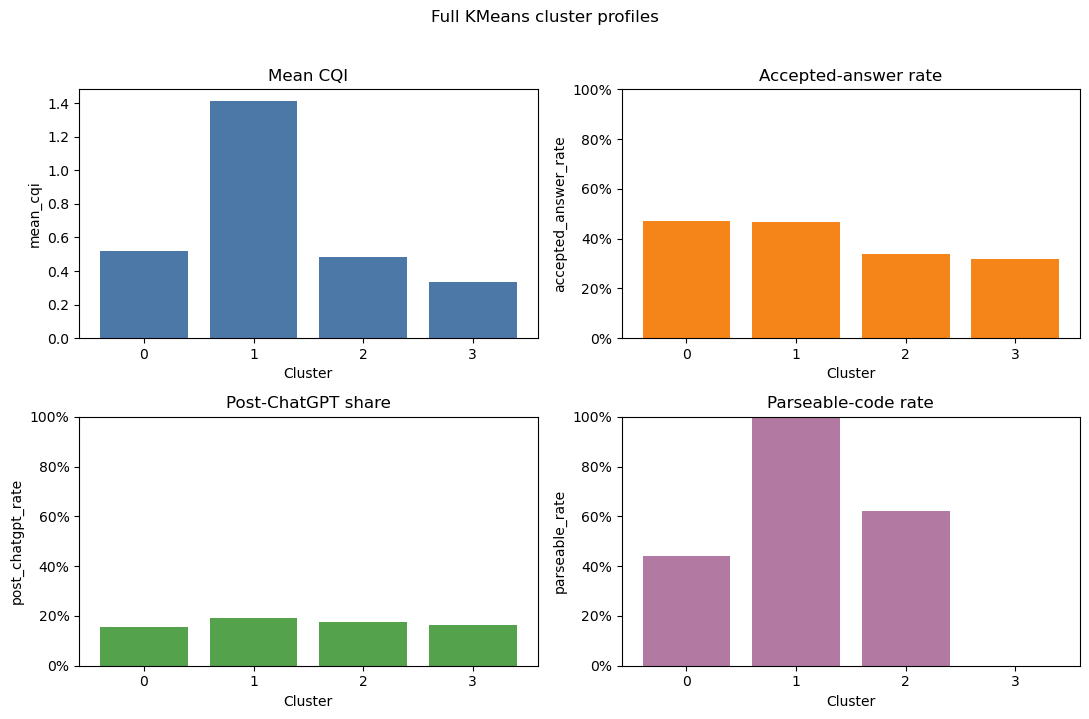

In [16]:
def plot_cluster_profiles(summary, run_label):
    summary = summary.sort_values("cluster").copy()
    summary["cluster"] = summary["cluster"].astype(str)
    profile_cols = ["mean_cqi", "accepted_answer_rate", "post_chatgpt_rate", "parseable_rate"]

    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    axes = axes.ravel()
    colors = ["#4c78a8", "#f58518", "#54a24b", "#b279a2"]
    titles = ["Mean CQI", "Accepted-answer rate", "Post-ChatGPT share", "Parseable-code rate"]

    for ax, col, color, title in zip(axes, profile_cols, colors, titles):
        ax.bar(summary["cluster"], summary[col], color=color)
        ax.set_title(title)
        ax.set_xlabel("Cluster")
        ax.set_ylabel(col)
        if col.endswith("rate") or col == "post_chatgpt_rate":
            ax.set_ylim(0, 1)
            ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

    fig.suptitle(f"{run_label.capitalize()} KMeans cluster profiles", y=1.02)
    plt.tight_layout()

    out = FIG_DIR / f"ml_kmeans_{run_label}_cluster_profiles.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    print("Saved", out)
    plt.show()

plot_cluster_profiles(computed["smoke_kmeans_summary"], "smoke")
plot_cluster_profiles(computed["full_kmeans_summary"], "full")

## 9. KMeans standardized centers heatmap

Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_smoke_centers_heatmap.png


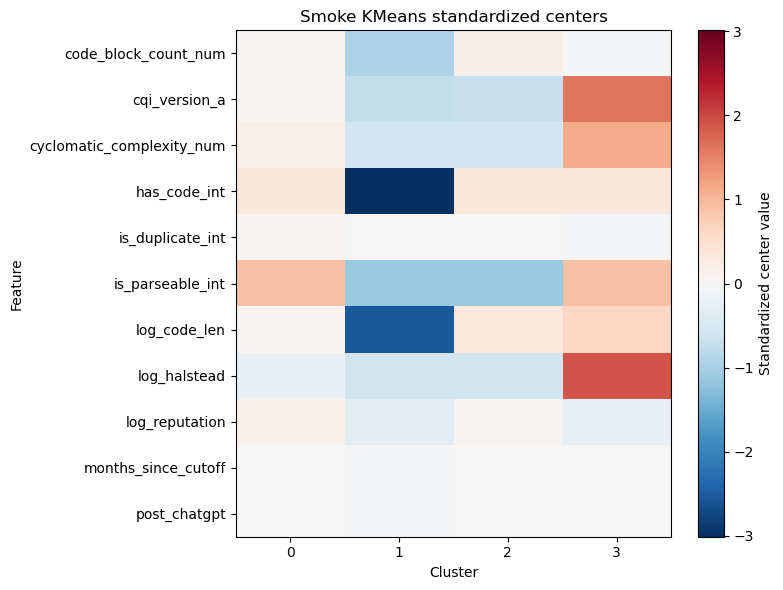

Saved /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_full_centers_heatmap.png


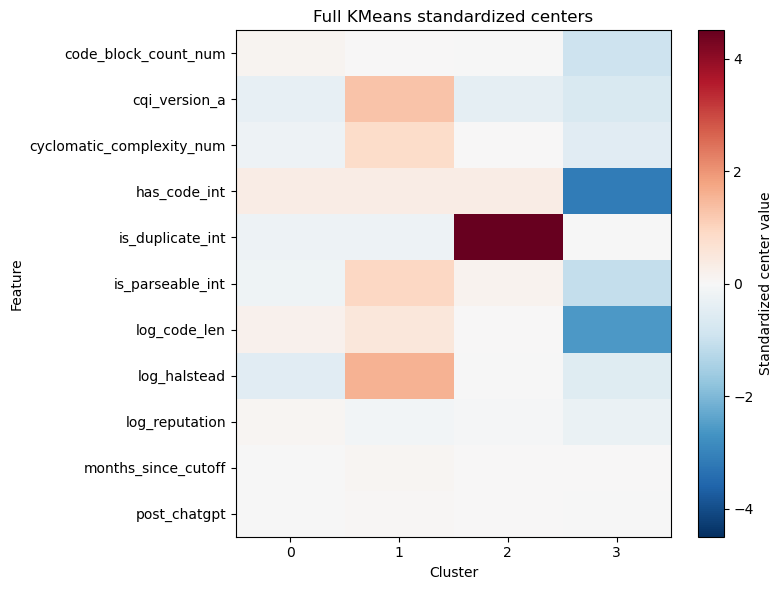

In [17]:
def plot_centers_heatmap(centers, run_label):
    pivot = centers.pivot(index="feature", columns="cluster", values="standardized_center_value")
    pivot = pivot.sort_index()

    fig, ax = plt.subplots(figsize=(8, 6))
    vmax = np.nanmax(np.abs(pivot.values))
    im = ax.imshow(pivot.values, cmap="RdBu_r", aspect="auto", vmin=-vmax, vmax=vmax)
    ax.set_title(f"{run_label.capitalize()} KMeans standardized centers")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Feature")
    ax.set_xticks(range(len(pivot.columns)), [str(c) for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), pivot.index)
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Standardized center value")
    plt.tight_layout()

    out = FIG_DIR / f"ml_kmeans_{run_label}_centers_heatmap.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    print("Saved", out)
    plt.show()

plot_centers_heatmap(computed["smoke_kmeans_centers"], "smoke")
plot_centers_heatmap(computed["full_kmeans_centers"], "full")

## 10. Report-ready summary

In [18]:
full = computed["full_metrics"].iloc[0]
full_k = computed["full_kmeans_metrics"].iloc[0]

print("Supervised full run")
print(f"Target mode: {full['target_mode']}")
print(f"Rows: train={int(full['n_train']):,}, test={int(full['n_test']):,}")
print(f"AUC={full['test_auc']:.4f}, Accuracy={full['test_accuracy']:.4f}, F1={full['test_f1']:.4f}")
print(f"Best regParam={full['best_regParam']}, elasticNetParam={full['best_elasticNetParam']}")

print("\nUnsupervised full KMeans")
print(f"k={int(full_k['k'])}, silhouette={full_k['silhouette']:.4f}, rows={int(full_k['n_rows']):,}")

print("\nSaved figures:")
for path in sorted(FIG_DIR.glob("*.png")):
    print("-", path)

Supervised full run
Target mode: accepted_answer
Rows: train=987,499, test=247,327
AUC=0.6881, Accuracy=0.6382, F1=0.6338
Best regParam=0.0, elasticNetParam=0.0

Unsupervised full KMeans
k=4, silhouette=0.4744, rows=1,234,826

Saved figures:
- /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_full_centers_heatmap.png
- /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_full_cluster_profiles.png
- /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_silhouette.png
- /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_smoke_centers_heatmap.png
- /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_kmeans_smoke_cluster_profiles.png
- /Users/1532016078qq.com/Desktop/MACS 30123/final/final_pj/outputs/ml/visualizations/ml_supervised_confusion_matrices.png
- /Users/1532016078qq.com/Desktop/MA

## 11. Close Dask client

In [19]:
client.close()
cluster.close()
print("Local Dask client closed.")

Terminated dask-25903046-worker-c19d20e8 (i-03ac06c1df9a2c889)
Terminated dask-25903046-worker-9567717c (i-0fc7c9e2ac085cacd)
Terminated dask-25903046-worker-cf5d45ec (i-0bd72445f257c73ba)
Terminated dask-25903046-worker-ae8063fd (i-0c2147c55b9b4123a)
Terminated dask-25903046-scheduler (i-0329f63d4f3e03de1)
Local Dask client closed.
